# 01 — Jump model router (prototype)

Regime router trained on **real daily data**. It uses a statistical jump model (JM) following
Shu, Yu & Mulvey (2024), `papers/shu_yu_mulvey2024_2402.05272.pdf`.

**Setup**
- Market signal: SPY excess return over T-bills (BIL)
- Features (paper, Table 2): EWM downside deviation (halflife 10), EWM Sortino ratio (halflife 20 and 60)
- Model: discrete JM with 2 states, jump penalty $\lambda = 50$ (the paper's typical value); continuous JM for soft probabilities
- Train: 2013-01 to 2024-08. Test (out of sample): 2024-09 to today

**Two kinds of labels**
- *In-sample* (`labels_`): fitted with the whole training window, including the future. Only for analysis.
- *Online* (`predict_online`): day $t$ uses only data up to $t$. This is what a router can actually use.
  Within the training window the model *parameters* still come from the full training window, so only the test period is truly out of sample.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from jumpmodels.jump import JumpModel
from jumpmodels.preprocess import DataClipperStd, StandardScalerPD

pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams["figure.figsize"] = (13, 4.5)

## Config

In [2]:
ASSETS = ["SPY", "TLT", "GLD", "DBC"]   # 4 risky assets
CASH = "BIL"                            # cash = T-bill ETF
DOWNLOAD_START = "2012-01-01"           # one year of warm-up for the EWM features
TRAIN_START, TRAIN_END = "2013-01-01", "2024-08-31"
TEST_START = "2024-09-01"

N_REGIMES = 2
JUMP_PENALTY = 50.0
REGIME_NAMES = {0: "Bull", 1: "Bear"}
REGIME_COLORS = {"Bull": "tab:green", "Neutral": "tab:orange", "Bear": "tab:red"}

## Data

In [3]:
px = yf.download(ASSETS + [CASH], start=DOWNLOAD_START, auto_adjust=True, progress=False)["Close"].dropna()
rets = px.pct_change().dropna()
excess = rets["SPY"] - rets[CASH]
print(f"{rets.index[0].date()} .. {rets.index[-1].date()}, {len(rets)} days")
rets.tail()

2012-01-04 .. 2026-11-20, 3743 days


Ticker,BIL,DBC,GLD,SPY,TLT
Date,,,,,
2026-11-16,0.000,-0.018,-0.007,-0.019,0.000
2026-11-17,0.000,-0.002,-0.001,-0.010,0.002
2026-11-18,0.000,-0.023,-0.032,-0.003,0.008
2026-11-19,0.000,0.004,-0.018,-0.020,0.002
2026-11-20,0.000,-0.010,-0.037,-0.036,0.014


## Features (Shu, Yu & Mulvey 2024, Table 2)

With excess return $R_t$ and EWM expectation $E_h$ at halflife $h$:
- downside deviation $DD_h = \sqrt{E_h[R_t^2 \, 1\{R_t < 0\}]}$
- Sortino ratio $S_h = E_h[R_t] / DD_h$

In [4]:
def ewm_dd(r: pd.Series, hl: float) -> pd.Series:
    return np.sqrt((r.clip(upper=0) ** 2).ewm(halflife=hl).mean())


def ewm_sortino(r: pd.Series, hl: float) -> pd.Series:
    return r.ewm(halflife=hl).mean() / ewm_dd(r, hl)


features = pd.DataFrame({
    "DD_10": ewm_dd(excess, 10),
    "Sortino_20": ewm_sortino(excess, 20),
    "Sortino_60": ewm_sortino(excess, 60),
}).loc[TRAIN_START:]

X_train_raw = features.loc[:TRAIN_END]
X_test_raw = features.loc[TEST_START:]

# clip and standardize with statistics from the training window only
clipper, scaler = DataClipperStd(mul=3.0), StandardScalerPD()
X_train = scaler.fit_transform(clipper.fit_transform(X_train_raw))
X_all = scaler.transform(clipper.transform(features))
features.describe()

,DD_10,Sortino_20,Sortino_60
count,3494.000,3494.000,3494.000
mean,0.006,0.136,0.101
std,0.004,0.179,0.089
min,0.001,-0.369,-0.179
25%,0.004,0.020,0.046
50%,0.005,0.138,0.105
75%,0.007,0.242,0.161
max,0.044,1.492,0.587


## Fit the jump model (discrete, 2 states)

In [5]:
jm = JumpModel(n_components=N_REGIMES, jump_penalty=JUMP_PENALTY, cont=False, random_state=0)
jm.fit(X_train, ret_ser=excess.loc[X_train.index], sort_by="cumret")

labels_insample = jm.labels_                      # train window, uses future data
labels_online = jm.predict_online(X_all)          # full period, causal

print("state means of SPY excess return (daily):", np.round(jm.ret_, 5))
print("state vols (daily):", np.round(jm.vol_, 4))
pd.DataFrame(jm.centers_, columns=X_train.columns, index=[REGIME_NAMES[k] for k in range(N_REGIMES)])

state means of SPY excess return (daily): [ 0.0008  -0.00027]
state vols (daily): [0.0072 0.0175]


,DD_10,Sortino_20,Sortino_60
Bull,-0.411,0.294,0.381
Bear,1.330,-0.952,-1.232


## Regime plot (like Fig. 4 in jrfm-13)

SPY price colored by regime. Top: in-sample labels (train only). Bottom: online labels over the whole period; the shaded area is the test period.

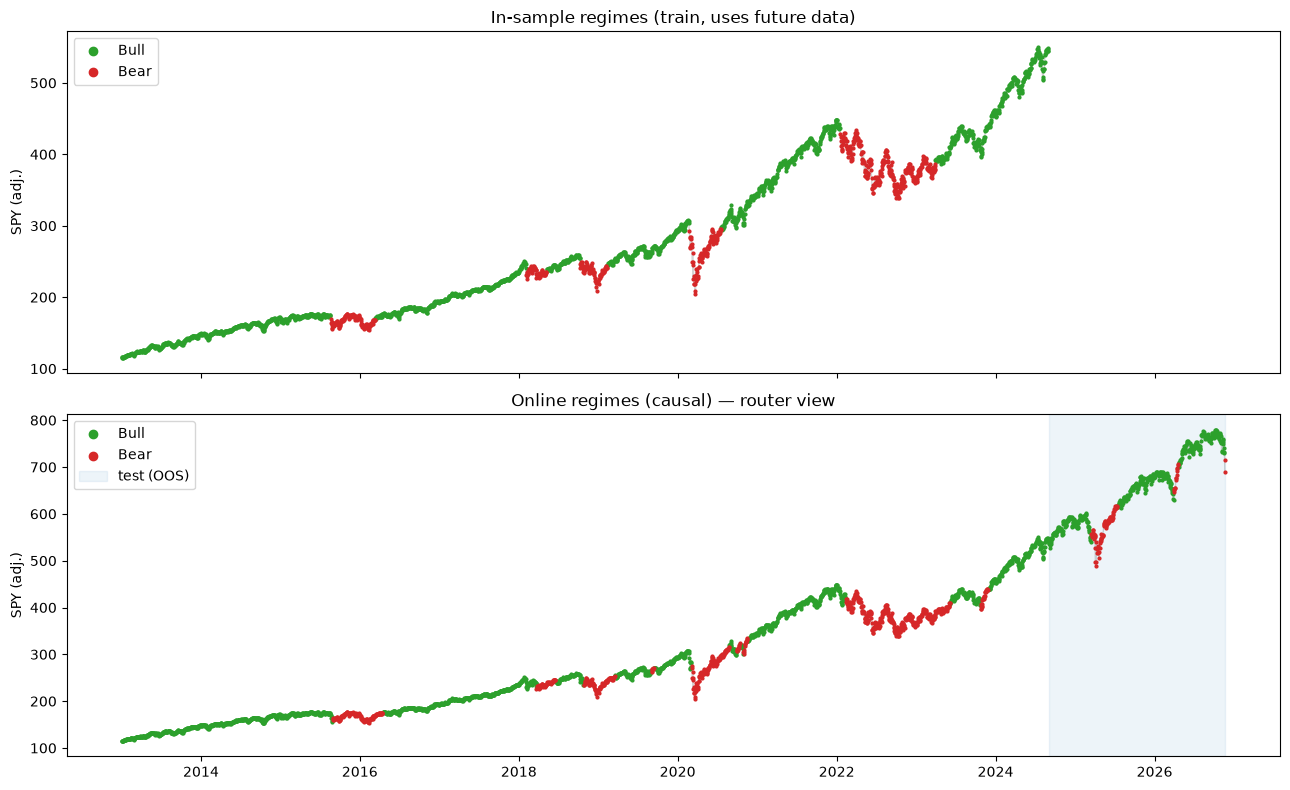

In [6]:
def plot_regimes(price: pd.Series, labels: pd.Series, title: str, ax, test_start=None, names=REGIME_NAMES):
    p = price.loc[labels.index]
    ax.plot(p.index, p.values, color="lightgrey", lw=1, zorder=1)
    for k in sorted(labels.unique()):
        m = labels == k
        ax.scatter(p.index[m], p.values[m], s=4, color=REGIME_COLORS[names[k]], label=names[k], zorder=2)
    if test_start is not None:
        ax.axvspan(pd.Timestamp(test_start), p.index[-1], color="tab:blue", alpha=0.08, label="test (OOS)")
    ax.set_title(title)
    ax.set_ylabel("SPY (adj.)")
    ax.legend(loc="upper left", markerscale=3)


fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
plot_regimes(px["SPY"], labels_insample, "In-sample regimes (train, uses future data)", axes[0])
plot_regimes(px["SPY"], labels_online, "Online regimes (causal) — router view", axes[1], test_start=TEST_START)
plt.tight_layout()

## Regime summaries (like Table 3 in jrfm-13, plus per asset)

In [7]:
def episodes(labels: pd.Series) -> pd.DataFrame:
    # one row per contiguous run of the same regime
    run_id = (labels != labels.shift()).cumsum()
    g = labels.groupby(run_id)
    return pd.DataFrame({"regime": g.first(), "start": g.apply(lambda s: s.index[0]), "days": g.size()})


def regime_summary(labels: pd.Series, rets: pd.DataFrame, cash: str = CASH) -> pd.DataFrame:
    ep = episodes(labels)
    years = len(labels) / 252
    rows = {}
    for k in sorted(labels.unique()):
        d = labels.index[labels == k]
        r = rets.loc[d]
        row = {
            "share of days": len(d) / len(labels),
            "episodes": int((ep.regime == k).sum()),
            "mean duration (days)": ep.loc[ep.regime == k, "days"].mean(),
            "median duration (days)": ep.loc[ep.regime == k, "days"].median(),
        }
        for a in ASSETS:
            ex = r[a] - r[cash]
            row[f"{a} ann. ret"] = r[a].mean() * 252
            row[f"{a} ann. vol"] = r[a].std() * np.sqrt(252)
            row[f"{a} Sharpe"] = ex.mean() / ex.std() * np.sqrt(252)
        rows[REGIME_NAMES.get(k, k)] = row
    print(f"regime switches per year: {(len(ep) - 1) / years:.2f}")
    return pd.DataFrame(rows)


def transition_matrix(labels: pd.Series) -> pd.DataFrame:
    names = [REGIME_NAMES.get(k, k) for k in sorted(labels.unique())]
    ct = pd.crosstab(labels.shift().dropna().astype(int), labels.iloc[1:])
    tm = ct.div(ct.sum(axis=1), axis=0)
    tm.index, tm.columns = names, names
    return tm

In [8]:
print("IN-SAMPLE, train window")
regime_summary(labels_insample, rets)

IN-SAMPLE, train window
regime switches per year: 0.86


,Bull,Bear
share of days,0.764,0.236
episodes,6.000,5.000
mean duration (days),373.833,138.600
median duration (days),367.500,102.000
SPY ann. ret,0.214,-0.056
SPY ann. vol,0.114,0.278
SPY Sharpe,1.764,-0.249
TLT ann. ret,0.019,0.008
TLT ann. vol,0.132,0.193
TLT Sharpe,0.056,-0.026


In [9]:
print("ONLINE, train window")
regime_summary(labels_online.loc[:TRAIN_END], rets)

ONLINE, train window
regime switches per year: 1.54


,Bull,Bear
share of days,0.721,0.279
episodes,10.000,9.000
mean duration (days),211.700,91.000
median duration (days),117.500,60.000
SPY ann. ret,0.134,0.191
SPY ann. vol,0.126,0.246
SPY Sharpe,0.982,0.712
TLT ann. ret,0.021,0.006
TLT ann. vol,0.130,0.187
TLT Sharpe,0.075,-0.050


In [10]:
print("ONLINE, test window (out of sample)")
regime_summary(labels_online.loc[TEST_START:], rets)

ONLINE, test window (out of sample)
regime switches per year: 2.26


,Bull,Bear
share of days,0.824,0.176
episodes,3.000,3.000
mean duration (days),153.333,32.667
median duration (days),148.000,14.000
SPY ann. ret,0.041,0.471
SPY ann. vol,0.132,0.280
SPY Sharpe,0.012,1.532
TLT ann. ret,-0.024,-0.029
TLT ann. vol,0.110,0.137
TLT Sharpe,-0.579,-0.510


In [11]:
print("Transition matrix, in-sample (rows: from, cols: to)")
display(transition_matrix(labels_insample))
print("Transition matrix, online train")
display(transition_matrix(labels_online.loc[:TRAIN_END]))

Transition matrix, in-sample (rows: from, cols: to)


,Bull,Bear
Bull,0.998,0.002
Bear,0.007,0.993


Transition matrix, online train


,Bull,Bear
Bull,0.996,0.004
Bear,0.011,0.989


## Online vs. in-sample: how late does the router notice?

For each in-sample switch in the training window: days until the online labels switch to the same regime (searched within 60 days).

In [12]:
def detection_delays(insample: pd.Series, online: pd.Series, max_lag: int = 60) -> pd.DataFrame:
    online = online.loc[insample.index]
    sw = insample.index[(insample != insample.shift()) & insample.shift().notna()]
    pos = {d: i for i, d in enumerate(online.index)}
    rows = []
    for d in sw:
        i, target = pos[d], insample.loc[d]
        window = online.iloc[i : i + max_lag + 1]
        hit = np.flatnonzero(window.values == target)
        rows.append({"switch date": d.date(), "to": REGIME_NAMES.get(target, target),
                     "delay (days)": int(hit[0]) if len(hit) else np.nan})
    return pd.DataFrame(rows)


delays = detection_delays(labels_insample, labels_online)
agree = (labels_online.loc[labels_insample.index] == labels_insample).mean()
print(f"agreement online vs in-sample (train): {agree:.1%}")
print(f"median delay: {delays['delay (days)'].median():.0f} days, mean: {delays['delay (days)'].mean():.1f}, "
      f"not detected within 60d: {delays['delay (days)'].isna().sum()} of {len(delays)}")
delays

agreement online vs in-sample (train): 90.3%
median delay: 24 days, mean: 22.8, not detected within 60d: 0 of 10


,switch date,to,delay (days)
0,2015-08-20,Bear,7
1,2016-03-11,Bull,24
2,2018-02-05,Bear,33
3,2018-05-09,Bull,28
4,2018-10-10,Bear,12
5,2019-02-12,Bull,24
6,2020-02-24,Bear,8
7,2020-07-20,Bull,27
8,2022-01-18,Bear,19
9,2023-03-31,Bull,46


## Jump penalty sensitivity

$\lambda = 0$ is plain k-means; larger $\lambda$ gives fewer, longer regimes, but also later detection.

In [13]:
rows = []
for lam in [0, 5, 10, 25, 50, 100, 200]:
    m = JumpModel(n_components=N_REGIMES, jump_penalty=lam, cont=False, random_state=0)
    m.fit(X_train, ret_ser=excess.loc[X_train.index], sort_by="cumret")
    on = m.predict_online(X_all)
    d = detection_delays(m.labels_, on)
    rows.append({
        "lambda": lam,
        "switches/yr in-sample": (len(episodes(m.labels_)) - 1) / (len(m.labels_) / 252),
        "switches/yr online (train)": (len(episodes(on.loc[:TRAIN_END])) - 1) / (len(on.loc[:TRAIN_END]) / 252),
        "switches/yr online (test)": (len(episodes(on.loc[TEST_START:])) - 1) / (len(on.loc[TEST_START:]) / 252),
        "bear share in-sample": (m.labels_ == 1).mean(),
        "median delay (days)": d["delay (days)"].median(),
    })
pd.DataFrame(rows).set_index("lambda")

,switches/yr in-sample,switches/yr online (train),switches/yr online (test),bear share in-sample,median delay (days)
lambda,,,,,
0,13.905,13.905,23.484,0.405,0.000
5,2.918,4.120,5.871,0.385,4.000
10,2.232,3.433,4.065,0.346,6.000
25,1.373,1.888,2.258,0.298,14.500
50,0.858,1.545,2.258,0.236,24.000
100,0.687,0.858,0.903,0.212,33.000
200,0.343,0.687,0.903,0.137,24.000


## Continuous jump model: soft probabilities (= soft gate)

Aydinhan, Kolm, Mulvey & Shu (2024): the state becomes a probability vector. These would be the MoE gating weights $p_t$.

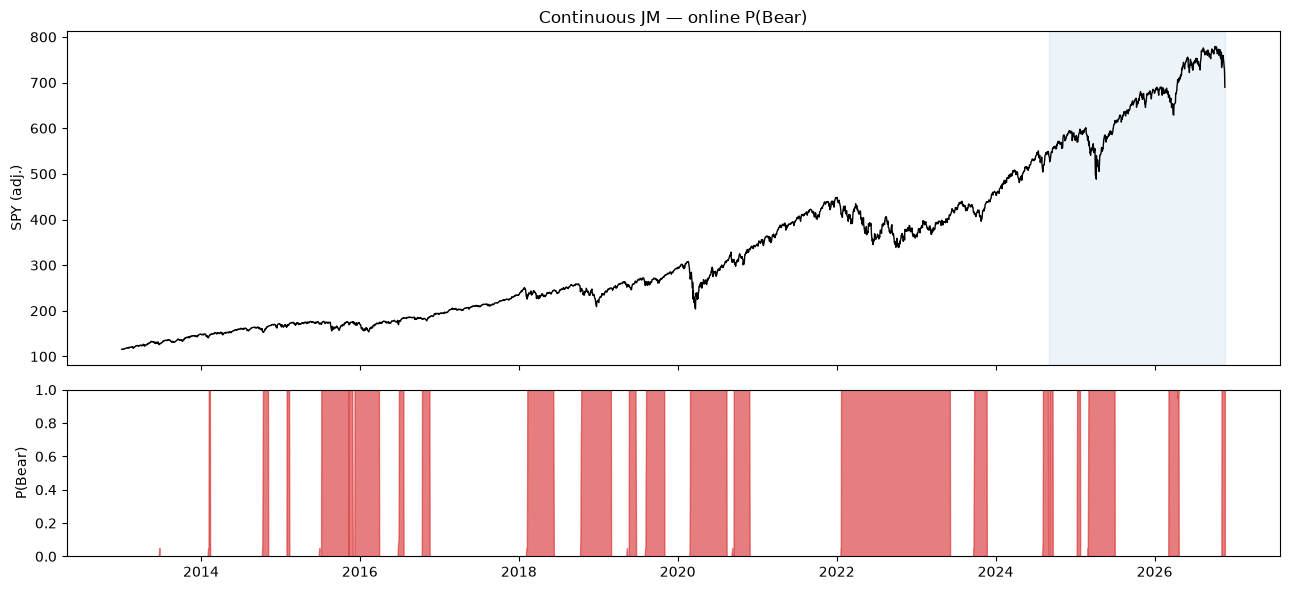

In [14]:
jmc = JumpModel(n_components=N_REGIMES, jump_penalty=JUMP_PENALTY, cont=True, random_state=0)
jmc.fit(X_train, ret_ser=excess.loc[X_train.index], sort_by="cumret")
proba_online = jmc.predict_proba_online(X_all)

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].plot(px["SPY"].loc[proba_online.index], color="black", lw=1)
axes[0].axvspan(pd.Timestamp(TEST_START), proba_online.index[-1], color="tab:blue", alpha=0.08)
axes[0].set_ylabel("SPY (adj.)")
axes[0].set_title("Continuous JM — online P(Bear)")
axes[1].fill_between(proba_online.index, proba_online.iloc[:, 1], color="tab:red", alpha=0.6)
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("P(Bear)")
plt.tight_layout()

## Three regimes (for comparison with jrfm-13)

regime switches per year: 1.03


,Bull,Neutral,Bear
share of days,0.443,0.429,0.128
episodes,5.000,5.000,3.000
mean duration (days),260.000,251.800,125.667
median duration (days),288.000,195.000,96.000
SPY ann. ret,0.247,0.134,-0.131
SPY ann. vol,0.106,0.145,0.334
SPY Sharpe,2.237,0.826,-0.428
TLT ann. ret,0.017,0.046,-0.082
TLT ann. vol,0.125,0.143,0.223
TLT Sharpe,0.054,0.219,-0.416


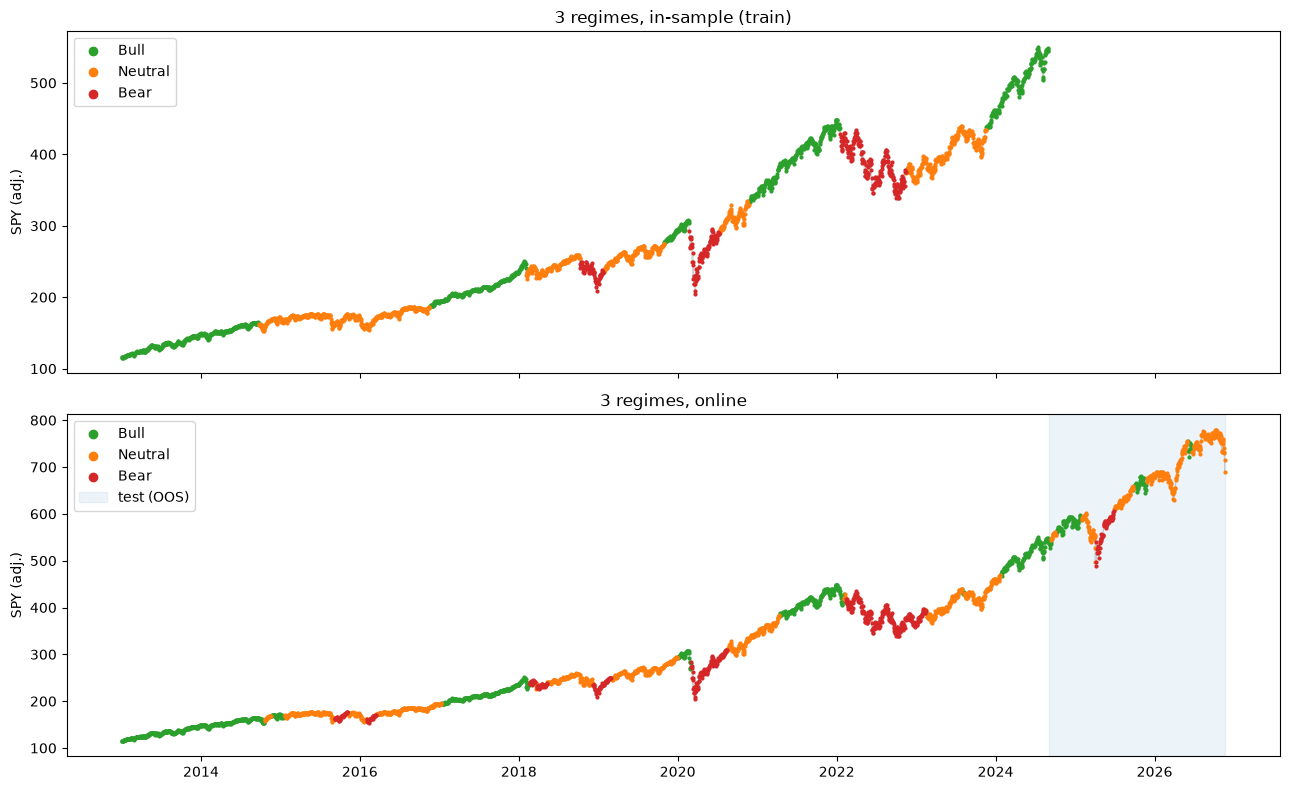

In [15]:
jm3 = JumpModel(n_components=3, jump_penalty=JUMP_PENALTY, cont=False, random_state=0)
jm3.fit(X_train, ret_ser=excess.loc[X_train.index], sort_by="cumret")
names3 = {0: "Bull", 1: "Neutral", 2: "Bear"}
on3 = jm3.predict_online(X_all)

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
plot_regimes(px["SPY"], jm3.labels_, "3 regimes, in-sample (train)", axes[0], names=names3)
plot_regimes(px["SPY"], on3, "3 regimes, online", axes[1], test_start=TEST_START, names=names3)
plt.tight_layout()

summary3 = regime_summary(jm3.labels_, rets)
summary3.columns = [names3[k] for k in range(3)]
summary3

## Notes / open points
- $\lambda$ is fixed at 50 here; the paper selects it by time-series cross-validation on the Sharpe ratio of a 0/1 strategy.
- The model is fitted once on the whole training window. A walk-forward refit (e.g. every 6 months, as in the paper) is the rigorous version.
- The continuous JM's probabilities are almost always 0 or 1, because the mode loss pushes them to the corners of the simplex. For a really soft gate, try `mode_loss=False`.
- 2 vs. 3 regimes: check whether the third regime is economically distinct (see the per-asset table) or just splits Bull.